# Prosody & Grammatical Categories — tidy pipeline

Distributional analysis of POS categories in a prosodic feature space,
SUD_French-Rhapsodie. This notebook supersedes `prosody_tidy_final.ipynb`.

**Structure**

| § | Content | Provenance |
|---|---------|------------|
| 1 | Configuration | new (was scattered) |
| 2 | Feature preprocessing | old cells 2–6, 10 (exclusion lists consolidated) |
| 3 | Corpus extraction & lexical units | old cells 7–9 + **new unit/category scheme** (supervisor points 1–2) |
| 4 | Matrices & feature spaces | old cells 11–14 + **new signal/perceptual spaces** (point 3) |
| 5 | Core metrics | old cells 18, 22, 25, 39, 58 |
| 6 | Paper baseline results | old cells 19, 23, 26–27, 42 |
| 7 | Experiment A: annotation-layer comparison | **new** (point 3) |
| 8 | Experiment B: revised categories — designed predictions | **new** (points 1–2) |
| 9 | Overlap analysis: bridge words, features, radar charts | old cells 28, 32, 35, 43–44, 57, 65–69 |
| 10 | Robustness: selection & displacement nulls | old cells 40–41, 69 |
| 11 | Experiment C: syllable-level categorisation | **new** (point 4) |

**Removed from the old notebook** (superseded or debug-only): cells 15–16, 20–21,
24, 30–31, 33–34, 36–38, 45–53, 56, 59–64. The non-mass pulling-feature
functions are gone (the by-mass versions replaced them); the first
`bridge_contrast` is gone (the revision with the length-proxy flag replaced it).

**The one switch that matters**: `CONFIG["unit_scheme"]` below. `"paper"`
reproduces the submitted paper exactly: units = (wordform, UPOS). `"revised"`
implements the supervisor's mixed scheme. Set it, then Run All.


In [1]:
import re
import sys
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

from scipy.stats import entropy
from sklearn.metrics.pairwise import cosine_similarity

# ── Paths ──────────────────────────────────────────────────────────────────
TOD_PATH      = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod"
GREX_PATH     = "/Users/madalina/Documents/M2TAL/stage/grex/grex2"
TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"
PATTERNS_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody.txt"

# ── Configuration ──────────────────────────────────────────────────────────
CONFIG = {
    # "paper"   : units = (wordform, UPOS), categories = UPOS. Reproduces the
    #             submitted paper.
    # "revised" : supervisor's mixed scheme —
    #             NOUN/PROPN/ADJ/DET/... -> (lemma, CAT)
    #             VERB                   -> (lemma, VERB:VerbForm)
    #             AUX                    -> (FORM, AUX:aux|cop|other)   [form-keyed:
    #                                       only 3 lemmas exist, lemma-keying leaves
    #                                       1–3 types per category]
    #             PRON                   -> (form, PRON_ton|PRON_aton)
    #             ADJ                    -> occurrence-level ADJ_pre|ADJ_post|ADJ_other
    "unit_scheme": "paper",

    # Re-include idiom-internal tokens as their own categories (NOUN_idiom, ...).
    # The paper EXCLUDES them; the supervisor suggested testing them instead.
    "include_idioms": False,

    # Categories with fewer distinct lexical-unit TYPES than this are dropped
    # from the analysis entirely (as focus units AND as neighbours). Rationale:
    # p_norm divides a neighbour's weight by its category's type frequency, so a
    # 1-type category (e.g. NUM in the first revised run) explodes into
    # meaningless matrix rows like NUM->AUX = 0.50.
    "min_types_per_category": 10,
    "always_drop_categories": {"X", "SYM", "PUNCT"},

    # Nearest-neighbour parameters (unchanged from the paper).
    "sim_threshold": 0.7,
    "max_neighbours": 20,

    # Columns non-zero on fewer lexical units than this are dropped (old cell 13).
    "min_lexunits_per_feature": 10,

    # p_norm denominator: "type" = share of lexical-unit types per category
    # (what the paper used); "token" also available via make_category_freqs.
    "freq_weighting": "type",
}

GREW_PATTERN = "pattern{X[upos<>PUNCT]}"

for p in (TOD_PATH, GREX_PATH):
    if p not in sys.path:
        sys.path.insert(1, p)

import pyximport
pyximport.install()

import grewpy
from grewpy import Corpus, CorpusDraft, Request

import tod.corpus            # noqa: F401  (registers handlers)
import grex.data             # noqa: F401
import grex.utils
import grex.features         # noqa: F401
import grex.data_prosody

grewpy.set_config("sud")
print(f"unit scheme: {CONFIG['unit_scheme']}")


connected to port: 62791


unit scheme: paper


## §2 Feature preprocessing

Everything that turns raw treebank annotations into feature strings:
what gets dropped, what gets binned, how SLAM contours are decomposed,
and the consolidated exclusion list (formerly one unstructured blob in cell 10).


In [2]:
# ── Features dropped at source (never become columns) ─────────────────────
FEATURES_TO_DROP = {
    # speaker-/recording-dependent, replaced by normalised equivalents
    'MeanF0', 'MeanF0Step', 'AvgAmplitude', 'MaxAmplitude',
    'BeforeMeanF0', 'BeforeMeanF0Step', 'BeforeAvgAmplitude',
    'NextMeanF0', 'NextMeanF0Step', 'NextAvgAmplitude',
    'AvgAmplitudeNormalized', 'MeanF0GlobalZscore', 'MeanF0LocalZscore',
    'MeanF0Normalized',
    # redundant with kept features
    'Semiton', 'Loc', 'Glo',
    # not linguistic
    'SylForm', 'AlignBegin', 'AlignEnd', 'pauseID',
    'Overlap', 'Backchannel', 'Nucleus', 'Onset',
}

# ── Continuous features binned into 3 corpus-wide quantile levels ─────────
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean', 'Duration',
    'BeforeSemitonesFromUtterance', 'NextSemitonesFromUtterance',
    'BeforeDuration', 'NextDuration',
    'BeforeSemiton', 'NextSemiton', 'NextSemitonsFromUtterance',
    'NextBreakLength',
    'AvgAmplitudeGlobalZscore', 'DurationGlobalZscore',   # used for Naija
}

BIN_LABELS = {
    'SemitonesFromUtteranceMean':   ['F0_low', 'F0_mid', 'F0_high'],
    'Duration':                     ['Dur_short', 'Dur_mid', 'Dur_long'],
    'BeforeSemitonesFromUtterance': ['BeforeF0_low', 'BeforeF0_mid', 'BeforeF0_high'],
    'NextSemitonesFromUtterance':   ['NextF0_low', 'NextF0_mid', 'NextF0_high'],
    'NextBreakLength':              ['NextBreak_short', 'NextBreak_mid', 'NextBreak_long'],
}


In [3]:
# ── SLAM3 contour decomposition ───────────────────────────────────────────
# *Tone features encode pitch contours compositionally:
#   [start][end]             (2 chars, no salient peak)
#   [start][end][peak][tier] (4 chars, with peak)
# pitch in {L,l,m,h,H}, tier in {1,2,3}, plus the atomic value 'Pause'.
# Decomposed into {start, end, peak, tier, has_peak, direction, magnitude}
# instead of ~300 sparse one-hot columns per *Tone feature.

SLAM_TONE_FEATURES = {'FootTone', 'GroupTone', 'PackageTone',
                      'Period_tone', 'Period', 'PeriodTone'}
_PITCH_LEVELS = {'L': 1, 'l': 2, 'm': 3, 'h': 4, 'H': 5}
_TIERS = {'1', '2', '3'}


def _parse_slam(label):
    if label == 'Pause':
        return {'pause': True, 'start': None, 'end': None, 'peak': None, 'tier': None}
    if len(label) == 2 and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS:
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': None, 'tier': None}
    if (len(label) == 4 and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS
            and label[2] in _PITCH_LEVELS and label[3] in _TIERS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': label[2], 'tier': label[3]}
    return None


def _slam_subfeatures(prefix, label):
    parsed = _parse_slam(label)
    if parsed is None:
        return
    if parsed['pause']:
        yield f"{prefix}:pause=True"
        return
    s, e = parsed['start'], parsed['end']
    yield f"{prefix}:start={s}"
    yield f"{prefix}:end={e}"
    delta = _PITCH_LEVELS[e] - _PITCH_LEVELS[s]
    direction = 'rise' if delta > 0 else ('fall' if delta < 0 else 'flat')
    yield f"{prefix}:direction={direction}"
    yield f"{prefix}:magnitude={abs(delta)}"
    if parsed['peak'] is not None:
        yield f"{prefix}:has_peak=True"
        yield f"{prefix}:peak={parsed['peak']}"
        yield f"{prefix}:tier={parsed['tier']}"
    else:
        yield f"{prefix}:has_peak=False"


In [4]:
# ── Binning & formatting helpers ──────────────────────────────────────────

def _normalise_duration(value_str):
    """Duration → milliseconds. Syllable nodes store ms, pause nodes seconds
    (values < 10 are seconds). Literal 0.0 means missing → None."""
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None
    return v * 1000 if v < 10 else v


def _is_sentinel(value_str):
    """True for the 0.0 sentinel on overlap / missing nodes."""
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False


def _feature_name(key):
    return key[-1]


def collect_continuous_values(all_data_items):
    """{feature_name: [float, ...]} over every occurrence, for thresholding."""
    collector = {f: [] for f in FEATURES_TO_BIN}
    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                elif not _is_sentinel(v):
                    try:
                        collector[fname].append(float(v))
                    except (ValueError, TypeError):
                        pass
    return collector


def compute_thresholds(collector, n_bins=3):
    thresholds = {}
    for fname, values in collector.items():
        if values:
            qs = np.linspace(0, 1, n_bins + 1)[1:-1]
            thresholds[fname] = np.quantile(np.array(values), qs).tolist()
    return thresholds


def _bin_value(fname, value_str, thresholds):
    if fname not in thresholds or _is_sentinel(value_str):
        return None
    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None
    if v is None:
        return None
    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]


def format_features(features, thresholds):
    """Feature dict → list of 'k1:k2:...=value' strings (binning + SLAM)."""
    result = []
    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)
        if fname in FEATURES_TO_DROP:
            continue
        values = value if isinstance(value, set) else {value}
        if fname in FEATURES_TO_BIN:
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
        elif fname in SLAM_TONE_FEATURES:
            for v in values:
                result.extend(_slam_subfeatures(prefix, v))
        else:
            for v in values:
                result.append(f"{prefix}={v}")
    return result


def _filter_features(features, excluded_patterns=None, included_patterns=None):
    out = []
    for feature in features:
        if excluded_patterns and any(re.search(p, feature) for p in excluded_patterns):
            continue
        if included_patterns and not any(re.search(p, feature) for p in included_patterns):
            continue
        out.append(feature)
    return out


In [5]:
# ── Excluded feature patterns, organised by REASON ────────────────────────
# (formerly one flat list in old cell 10; contents identical, grouped and
# deduplicated so each exclusion is auditable)

_EXCL_WOULD_REVEAL_POS = [
    # the unit's own identity / morphosyntax — would trivially recover the category
    'upos', 'lemma', 'form', 'rel_shallow', 'deprel', 'rel_deep=', '__MISC__Rel=',
    'Case', 'Definite', 'Gender', 'Mood', 'Number', 'NumType', 'Person',
    'Polarity', 'Poss', 'PronType', 'Reflex', 'Tense', 'VerbForm', 'Voice',
    'Number\\[lex\\]', 'Person\\[lex\\]', 'Gender\\[ctxt\\]', 'Number\\[ctxt\\]',
    'ExtPos', 'HasSpokenGender', 'HasSpokenNumber', 'Emph', 'Subject=',
]
_EXCL_NOT_PROSODIC = [
    # orthography / alignment / metadata
    'Foreign', 'Lang', 'AlignBegin', 'AlignEnd', 'SylForm', 'SpaceAfter',
    'Token2=', 'Token3', 'Token4', 'TypePara=', 'TypeInherited=', 'Truncated=',
    'own:Filler=', 'Filler=', 'Layer', 'Shared',
    # macrosyntactic (IU/Nucleus are ILLOCUTIONARY units, not prosodic ones —
    # keeping them would smuggle macrosyntax into the "prosody" spaces)
    'IU', 'nucleus', 'Nucleus',
]
_EXCL_REDUNDANT_OR_NOISE = [
    'Slope=X',                       # unmeasurable slope
    'Fused=Yes',                     # rare, per-syllable, hurts signal/noise
    ':Slope=',                       # local slope; the Glo scope is kept
    'ProminenceFinal=0', 'ProminenceInitial=0',   # absence-of-annotation zeros
    'UtteranceMeanF0=0.0', 'Loc=', 'direction=flat', 'has_peak=False',
    'AvgAmplitudeLocalZscore', 'DurationLocalZscore', 'MaxAmplitudeLocalZscore',
    'DurationNormalized', 'MaxAmplitudeGlobalZscore', 'MaxAmplitudeNormalized',
    'Coda',
]

EXCLUDED_FEATURE_PATTERNS = (
    _EXCL_WOULD_REVEAL_POS + _EXCL_NOT_PROSODIC + _EXCL_REDUNDANT_OR_NOISE
)
print(f"{len(EXCLUDED_FEATURE_PATTERNS)} exclusion patterns "
      f"({len(_EXCL_WOULD_REVEAL_POS)} POS-revealing, "
      f"{len(_EXCL_NOT_PROSODIC)} non-prosodic, "
      f"{len(_EXCL_REDUNDANT_OR_NOISE)} redundant/noise)")


65 exclusion patterns (30 POS-revealing, 19 non-prosodic, 16 redundant/noise)


## §3 Corpus extraction & lexical units

Old cells 7–9 plus the new unit/category scheme. The invariant everything
downstream relies on: **a lexical unit is a 2-tuple `(unit_id, category)` and
the category always lives in slot 1** — so the paper scheme and the revised
scheme are interchangeable without touching any analysis code.


In [6]:
# ── Load corpus & search ──────────────────────────────────────────────────
corpus = grewpy.Corpus(TREEBANK_PATH)
draft  = grewpy.CorpusDraft(corpus)

_req = (grewpy.Request(GREW_PATTERN)
        .without("X[InTitle=Yes]").without("X[Title=Yes]")
        .without("X[Scrap=Yes]").without("X[Foreign]").without("X[Lang]")
        .without("X-[fixed]->Y").without("Y-[flat:name]->X")
        .without("Y-[goeswith]->X"))
if not CONFIG["include_idioms"]:
    # The PAPER excludes idiom-internal tokens. Supervisor point 2 suggests
    # testing them as their own categories instead: set include_idioms=True.
    _req = _req.without("X[InIdiom=Yes]").without("X[Idiom=Yes]")

all_matches = corpus.search(_req, clustering_keys=["X.form"])
matches = all_matches            # no frequency filter at the form level

sent_id_to_sentence = {
    draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft))  # type: ignore
}
print(f"distinct word forms matched: {len(matches)}")


distinct word forms matched: 4567


In [7]:
# ── Occurrence-level syntactic context sets (revised scheme only) ─────────
# Category splits that depend on the occurrence's syntactic context are
# precomputed as (sent_id, node_id) sets with one grew search each, so that
# category assignment below is a set lookup.
#
# NB: verify the three patterns in the grew web UI against the current
# Rhapsodie release before trusting a new run (comp:aux / comp:pred naming).

def _match_node_set(pattern, node="A"):
    return {(m["sent_id"], str(m["matching"]["nodes"][node]))
            for m in corpus.search(grewpy.Request(pattern))}

if CONFIG["unit_scheme"] == "revised":
    ADJ_PRENOMINAL = _match_node_set(
        'pattern{N-[mod]->A; A[upos=ADJ]; N[upos=NOUN|PROPN]; A << N}')
    ADJ_POSTNOMINAL = _match_node_set(
        'pattern{N-[mod]->A; A[upos=ADJ]; N[upos=NOUN|PROPN]; N << A}')
    AUX_TRUE   = _match_node_set('pattern{A[upos=AUX]; A-[1=comp, 2=aux]->V}')
    AUX_COPULA = _match_node_set('pattern{A[upos=AUX]; A-[1=comp, 2=pred]->P}')
    print(f"ADJ pre/post occurrences: {len(ADJ_PRENOMINAL)} / {len(ADJ_POSTNOMINAL)}")
    print(f"AUX aux/cop occurrences:  {len(AUX_TRUE)} / {len(AUX_COPULA)}")
else:
    ADJ_PRENOMINAL = ADJ_POSTNOMINAL = AUX_TRUE = AUX_COPULA = set()


In [8]:
# ── Pronoun tonicity (revised scheme) ─────────────────────────────────────
# Assignment order: PronType rules first (Rel -> atonic; Dem -> atonic iff
# lemma 'ce'), then NumType (numeral pronouns -> tonic), then the form lexicon.
# Leading hyphens are stripped first, so the inversion enclitics -il, -tu,
# -on, -vous resolve through the clitic lexicon (they are postverbal clitics —
# prosodically interesting in their own right, but atonic).
#
# KNOWN HOMOGRAPHS a form lexicon cannot resolve: lui (dative clitic vs
# tonic), elle(s), nous, vous. Defaulted to CLITIC (far more frequent in
# speech); occurrence-level resolution via deprel is a question for Sylvain.

PRON_ATONIC = {
    "je", "j'", "j~", "tu", "t'", "il", "ils", "elle", "elles", "on", "l'on",
    "nous", "vous",
    "me", "m'", "te", "se", "s'", "le", "la", "les", "l'",
    "lui", "leur", "y", "en",
    "ce", "c'", "ç'",
    "que", "qu'", "qui", "dont", "où",           # relatives
}
PRON_TONIC = {
    "moi", "toi", "soi", "eux",
    "ça", "cela", "ceci",
    "celui", "celle", "ceux", "celles",
    "celui-ci", "celui-là", "celle-ci", "celle-là",
    "ceux-ci", "ceux-là", "celles-ci", "celles-là",
    "chacun", "chacune", "quelqu'un", "quelqu'une",
    "quelques-uns", "quelques-unes",
    "personne", "rien", "tout", "tous", "toutes",
    "autre", "autres", "autrui", "aucun", "aucune",
    "certains", "certaines", "plusieurs", "beaucoup",
    "quoi", "quel", "quels", "quelle", "quelles",
    "lequel", "laquelle", "lesquels", "lesquelles",
    "lui-même", "elle-même", "eux-mêmes", "elles-mêmes",
    "moi-même", "toi-même", "soi-même", "nous-mêmes", "vous-mêmes",
    "un", "une", "uns", "unes",                   # pronominal numerals
}

_unknown_prons = Counter()

def pron_tonicity(form, token_features):
    f = form.lower().lstrip('-')
    ptype = token_features.get("PronType")
    if ptype == "Rel":
        return "PRON_aton"
    if ptype == "Dem":
        return "PRON_aton" if token_features.get("lemma", f) == "ce" else "PRON_ton"
    if token_features.get("NumType"):             # deux, trente, mille, ...
        return "PRON_ton"
    if f in PRON_ATONIC:
        return "PRON_aton"
    if f in PRON_TONIC:
        return "PRON_ton"
    _unknown_prons[form.lower()] += 1
    return "PRON_ton"   # open-class default; review _unknown_prons after the run


In [9]:
# ── Unit + category assignment ────────────────────────────────────────────

def assign_unit_and_category(form, tf, sent_id, node_id):
    """One occurrence -> (unit_id, category), or None to skip.

    paper   : (wordform, UPOS)  [ExtPos wins over upos, as before]
    revised : the mixed scheme (see CONFIG comment). ADJ position and AUX
              function are occurrence-level, so e.g. (grand, ADJ_pre) and
              (grand, ADJ_post) are two distinct lexical units — the concrete
              form of "predicting the construction rather than the POS".
    """
    pos = tf.get("ExtPos") or tf.get("upos")
    if pos is None:
        return None

    if CONFIG["unit_scheme"] == "paper":
        return (form, pos)

    lemma = tf.get("lemma", form)
    if CONFIG["include_idioms"] and tf.get("InIdiom") == "Yes":
        return (lemma, f"{pos}_idiom")

    occ = (sent_id, node_id)
    if pos == "VERB":
        return (lemma, f"VERB:{tf.get('VerbForm', 'Fin')}")
    if pos == "AUX":
        # FORM-keyed: est / était / seraient genuinely differ prosodically,
        # and lemma-keying a 3-lemma category leaves 1–3 types per cell.
        # VerbForm deliberately NOT crossed in (too fine for 3 lemmas).
        if occ in AUX_TRUE:
            return (form.lower(), "AUX:aux")
        if occ in AUX_COPULA:
            return (form.lower(), "AUX:cop")
        return (form.lower(), "AUX:other")   # should be small — check inventory
    if pos == "PRON":
        return (form.lower(), pron_tonicity(form, tf))
    if pos == "ADJ":
        if occ in ADJ_POSTNOMINAL:
            return (lemma, "ADJ_post")
        if occ in ADJ_PRENOMINAL:
            return (lemma, "ADJ_pre")
        return (lemma, "ADJ_other")          # predicative, detached, ...
    return (lemma, pos)


match_units = {}
for form, occurrences in matches.items():
    for m in occurrences:
        sent_id = m["sent_id"]
        node_id = str(m["matching"]["nodes"]["X"])
        sentence_features = sent_id_to_sentence.get(sent_id)
        if sentence_features is None or node_id not in sentence_features:
            continue
        res = assign_unit_and_category(form, sentence_features[node_id],
                                       sent_id, node_id)
        if res is not None:
            match_units.setdefault(res, []).append(m)

inventory = Counter(cat for (_, cat) in match_units)
print(f"(unit, category) pairs before pruning: {len(match_units)}")
print("category inventory:", inventory.most_common())
if _unknown_prons:
    print("\nPRON forms outside PronType/NumType rules and both lexica "
          "(defaulted to tonic) — review:")
    print(_unknown_prons.most_common(20))


(unit, category) pairs before pruning: 4880
category inventory: [('NOUN', 1820), ('VERB', 1382), ('ADJ', 639), ('PROPN', 480), ('ADV', 200), ('PRON', 108), ('DET', 88), ('AUX', 48), ('ADP', 39), ('INTJ', 29), ('X', 20), ('CCONJ', 13), ('SCONJ', 13), ('NUM', 1)]


In [10]:
# ── Prune unusable categories ─────────────────────────────────────────────
# Categories dropped here disappear from the analysis entirely: as focus
# units AND as neighbours. See CONFIG["min_types_per_category"] for why.

_min_types = CONFIG["min_types_per_category"]
_dropped = {c for c, n in inventory.items()
            if n < _min_types or c in CONFIG["always_drop_categories"]}
if _dropped:
    n_before = len(match_units)
    match_units = {k: v for k, v in match_units.items() if k[1] not in _dropped}
    print(f"dropped categories (<{_min_types} types or always-drop): "
          f"{sorted(_dropped)}")
    print(f"units: {n_before} -> {len(match_units)}")

CATEGORIES = sorted({cat for (_, cat) in match_units})
N_CATEGORIES = len(CATEGORIES)
print(f"\n{N_CATEGORIES} categories in play -> chance baseline "
      f"1/N = {1 / N_CATEGORIES:.3f}")
print(CATEGORIES)


dropped categories (<10 types or always-drop): ['NUM', 'X']
units: 4880 -> 4859

12 categories in play -> chance baseline 1/N = 0.083
['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'PRON', 'PROPN', 'SCONJ', 'VERB']


In [11]:
# ── Feature extraction over every occurrence ──────────────────────────────
with open(PATTERNS_FILE) as f:
    _config_yaml = yaml.load(f, Loader=yaml.Loader)

_templates = grex.utils.FeaturePredicate.from_config(_config_yaml["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    _config_yaml["features"], templates=_templates)

all_data_items = []
for lex_unit, mts in match_units.items():
    for match in mts:
        feats = grex.data_prosody.extract_features(draft, match, feature_predicate)
        all_data_items.append((lex_unit, match, feats))
print(f"(lex_unit, match, features) triples: {len(all_data_items)}")

thresholds = compute_thresholds(collect_continuous_values(all_data_items))
print("\nbinning thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1', 'Q2', 'Q3'])
    print(f"  {fname}: <{bounds[0]:.3f} -> {labels[0]} | "
          f"<{bounds[1]:.3f} -> {labels[1]} | >= -> {labels[2]}")

data = {k: [] for k in match_units}
for lex_unit, _, features in all_data_items:
    data[lex_unit].append(_filter_features(
        format_features(features, thresholds),
        excluded_patterns=EXCLUDED_FEATURE_PATTERNS))


(lex_unit, match, features) triples: 33083

binning thresholds:
  SemitonesFromUtteranceMean: <-1.277 -> F0_low | <0.530 -> F0_mid | >= -> F0_high
  NextBreakLength: <0.284 -> NextBreak_short | <0.530 -> NextBreak_mid | >= -> NextBreak_long
  Duration: <132.000 -> Dur_short | <199.000 -> Dur_mid | >= -> Dur_long


## §4 Matrices & feature spaces

Old cells 11–14 merged, plus the three **new annotation-layer spaces**
(supervisor point 3):

- `signal_strict` — syllable-tier acoustics only (Duration, AvgHeightGlo,
  PitchRangeGlo, SlopeGlo, Semitones). Fully automatic from the signal (on
  manually corrected alignment): nothing here was produced by a human judgment.
- `signal_contours` — adds the decomposed SLAM tonal sub-features. Values are
  automatic, but the constituents whose contours they describe come from the
  perceptual segmentation → intermediate status, report with that caveat.
- `perceptual_struct` — Foot/Group/Package positions & types, RhythmGroup,
  Prominence, Hesitation: everything built from the native listeners' S/W/_
  prominence judgments.

All three are intersected with the `prosody_pure` positional scope
(own / prev / next) so the annotation-layer comparison isn't confounded by
different context windows.


In [12]:
# ── Feature matrix ────────────────────────────────────────────────────────
unique_units    = sorted(data)
unique_features = sorted({f for lists in data.values() for fs in lists for f in fs})

idx2lexunit = dict(enumerate(unique_units))
lexunit2idx = {u: i for i, u in idx2lexunit.items()}
idx2feature = dict(enumerate(unique_features))
feature2idx = {f: i for i, f in idx2feature.items()}

co_occurrence_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
for lex_unit, feature_lists in data.items():
    for feature_list in feature_lists:
        for feature in feature_list:
            co_occurrence_matrix[lexunit2idx[lex_unit], feature2idx[feature]] += 1

n_occ = np.array([len(data[idx2lexunit[i]]) for i in range(len(idx2lexunit))],
                 dtype=float)
feature_matrix = np.divide(
    co_occurrence_matrix, n_occ[:, None],
    out=np.zeros_like(co_occurrence_matrix), where=n_occ[:, None] != 0)

# Column-frequency filter: columns non-zero on very few units are noise axes.
# Cosine similarity is scale-invariant, so rows are not renormalised after.
_keep = (co_occurrence_matrix > 0).sum(axis=0) >= CONFIG["min_lexunits_per_feature"]
n_cols_before = feature_matrix.shape[1]
co_occurrence_matrix = co_occurrence_matrix[:, _keep]
feature_matrix       = feature_matrix[:, _keep]
idx2feature = dict(enumerate(f for i, f in sorted(idx2feature.items()) if _keep[i]))
feature2idx = {f: i for i, f in idx2feature.items()}
print(f"lexical units: {len(idx2lexunit)}   "
      f"features: {len(idx2feature)} (dropped {n_cols_before - len(idx2feature)} "
      f"rare columns)")


lexical units: 4859   features: 927 (dropped 10663 rare columns)


In [13]:
# ── Feature-space masks & similarities ────────────────────────────────────
PROSODIC_MARKERS = (
    'childSyl', 'prevSyl', 'nextSyl',
    'Slope', 'Glo', 'Loc', 'Duration', 'PitchRange', 'AvgHeight', 'Semiton',
    'F0', 'Fused',
    'Foot', 'Group', 'Package', 'Period',
    'Prominence', 'Hesitation', 'RhythmGroup', 'NextBreakLength', 'IU', 'Nucleus',
)
PROSODY_PURE_MARKERS = ('own', 'childSyl', 'prevSyl', 'nextSyl', 'prev:', 'next:')

# Annotation-layer markers (new).
_SIGNAL_SYL_MARKERS = ('childSyl', 'prevSyl', 'nextSyl')
_TONE_MARKER        = 'Tone:'
_PERCEPTUAL_MARKERS = ('Foot=', 'Group=', 'Package=',
                       'FootType', 'RhythmGroup', 'PackageType', 'Package_type',
                       'Prominence', 'Hesitation')


def _mask_for(markers):
    return np.array([any(p in f for p in markers) for f in idx2feature.values()])


prosodic_mask     = _mask_for(PROSODIC_MARKERS)
syntactic_mask    = ~prosodic_mask
prosody_pure_mask = _mask_for(PROSODY_PURE_MARKERS)

signal_strict_mask = np.array([
    any(m in f for m in _SIGNAL_SYL_MARKERS) and _TONE_MARKER not in f
    for f in idx2feature.values()]) & prosody_pure_mask
signal_contours_mask = np.array([
    (any(m in f for m in _SIGNAL_SYL_MARKERS) or _TONE_MARKER in f)
    and not any(m in f for m in _PERCEPTUAL_MARKERS)
    for f in idx2feature.values()]) & prosody_pure_mask
perceptual_struct_mask = _mask_for(_PERCEPTUAL_MARKERS) & prosody_pure_mask

SPACE_MASKS = {
    "syntactic":          syntactic_mask,
    "prosodic_syntactic": prosodic_mask,
    "prosody_pure":       prosody_pure_mask,
    "signal_strict":      signal_strict_mask,
    "signal_contours":    signal_contours_mask,
    "perceptual_struct":  perceptual_struct_mask,
    "combined":           None,
}
similarities = {}
for name, mask in list(SPACE_MASKS.items()):
    n = feature_matrix.shape[1] if mask is None else int(mask.sum())
    if n == 0:
        print(f"{name:20s}     0 columns — SKIPPED")
        del SPACE_MASKS[name]
        continue
    similarities[name] = cosine_similarity(
        feature_matrix if mask is None else feature_matrix[:, mask])
    print(f"{name:20s} {n:5d} columns")

# Audit: read a sample of each annotation-layer mask — substring matching is
# only as good as the marker lists.
for name in ("signal_strict", "signal_contours", "perceptual_struct"):
    feats = [f for i, f in idx2feature.items() if SPACE_MASKS[name][i]]
    print(f"\n--- {name}: first 12 of {len(feats)} ---")
    for f in feats[:12]:
        print("   ", f)


syntactic                8 columns
prosodic_syntactic     919 columns
prosody_pure           604 columns
signal_strict          124 columns
signal_contours        448 columns
perceptual_struct      144 columns
combined               927 columns

--- signal_strict: first 12 of 124 ---
    node:X:childSyl1:AvgHeightGlo=H
    node:X:childSyl1:AvgHeightGlo=L
    node:X:childSyl1:AvgHeightGlo=M
    node:X:childSyl1:Duration=Dur_long
    node:X:childSyl1:Duration=Dur_mid
    node:X:childSyl1:Duration=Dur_short
    node:X:childSyl1:ExternalOnset=True
    node:X:childSyl1:PitchRangeGlo=H
    node:X:childSyl1:PitchRangeGlo=L
    node:X:childSyl1:PitchRangeGlo=M
    node:X:childSyl1:SemitonesFromUtteranceMean=F0_high
    node:X:childSyl1:SemitonesFromUtteranceMean=F0_low

--- signal_contours: first 12 of 448 ---
    node:X:childSyl1:AvgHeightGlo=H
    node:X:childSyl1:AvgHeightGlo=L
    node:X:childSyl1:AvgHeightGlo=M
    node:X:childSyl1:Duration=Dur_long
    node:X:childSyl1:Duration=Dur_mid
 

In [14]:
# ── Category frequencies & syllable counts ────────────────────────────────

def make_category_freqs(idx2lexunit, n_occ, weight_by="type"):
    """p_norm denominator. 'type': share of lexical-unit types per category
    (the paper's choice). 'token': share of occurrences."""
    if weight_by == "type":
        counts = Counter(lu[1] for lu in idx2lexunit.values())
    else:
        counts = Counter()
        for i, lu in idx2lexunit.items():
            counts[lu[1]] += n_occ[i]
    total = sum(counts.values())
    return {cat: c / total for cat, c in counts.items()}


category_freqs_type  = make_category_freqs(idx2lexunit, n_occ, "type")
category_freqs_token = make_category_freqs(idx2lexunit, n_occ, "token")
category_freqs = (category_freqs_type if CONFIG["freq_weighting"] == "type"
                  else category_freqs_token)

# Syllable count per unit, from which childSyl slots are populated.
SYL_SLOT_RE = re.compile(r"childSyl(\d+):")
_syl_slot_cols = defaultdict(list)
for i, feat in idx2feature.items():
    m = SYL_SLOT_RE.search(feat)
    if m:
        _syl_slot_cols[int(m.group(1))].append(i)

n_syl = np.ones(len(idx2lexunit), dtype=int)
for k in sorted(_syl_slot_cols):
    present = (feature_matrix[:, _syl_slot_cols[k]] > 0).any(axis=1)
    n_syl[present] = np.maximum(n_syl[present], k)

syl_df = pd.DataFrame({
    "lex_unit": [idx2lexunit[i] for i in range(len(idx2lexunit))],
    "POS":      [idx2lexunit[i][1] for i in range(len(idx2lexunit))],
    "n_syl":    n_syl,
    "n_occ":    n_occ,
})


## §5 Core metrics

`compute_scores` (per-unit purity / entropy / rival), `build_transition_matrix`
(the stability matrix), block shares **with the correct per-class chance level**
(new — with unequal block sizes the two classes no longer share a 45% baseline),
the exact-enumeration modularity check, and weighted average stability.


In [15]:
def compute_scores(similarity, idx2lexunit, category_freqs,
                   sim_threshold=None, max_neighbours=None):
    """{(unit, cat): {purity, entropy, rival_category, rival_weight_ratio}}"""
    sim_threshold = sim_threshold or CONFIG["sim_threshold"]
    max_neighbours = max_neighbours or CONFIG["max_neighbours"]
    scores = {}
    for idx, lex_unit in idx2lexunit.items():
        current = lex_unit[1]
        cand = np.where(similarity[idx] >= sim_threshold)[0]
        neigh = sorted([i for i in cand if i != idx],
                       key=lambda i: similarity[idx][i], reverse=True)[:max_neighbours]
        if not neigh:
            continue
        w_by_cat, total_w = {}, 0.0
        for n_i in neigh:
            w = similarity[idx][n_i]
            w_by_cat[idx2lexunit[n_i][1]] = w_by_cat.get(idx2lexunit[n_i][1], 0) + w
            total_w += w
        norm = {c: (w / total_w) / category_freqs[c] for c, w in w_by_cat.items()}
        z = sum(norm.values())
        p_norm = {c: v / z for c, v in norm.items()}

        rival_cat, rival_p = None, 0.0
        for c, p in p_norm.items():
            if c != current and p > rival_p:
                rival_cat, rival_p = c, p
        scores[lex_unit] = {
            "purity":             p_norm.get(current, 0.0),
            "entropy":            entropy(list(p_norm.values())),
            "rival_category":     rival_cat,
            "rival_weight_ratio": rival_p,
        }
    return scores


In [16]:
def build_transition_matrix(similarity, idx2lexunit, category_freqs,
                            sim_threshold=None, max_neighbours=None):
    """Square row-stochastic stability matrix indexed by category."""
    sim_threshold = sim_threshold or CONFIG["sim_threshold"]
    max_neighbours = max_neighbours or CONFIG["max_neighbours"]
    rows = []
    for idx, lex_unit in idx2lexunit.items():
        current = lex_unit[1]
        cand = np.where(similarity[idx] > sim_threshold)[0]
        neigh = sorted([i for i in cand if i != idx],
                       key=lambda i: similarity[idx][i], reverse=True)[:max_neighbours]
        if not neigh:
            continue
        raw, tot = {}, 0.0
        for n_i in neigh:
            w = similarity[idx][n_i]
            raw[idx2lexunit[n_i][1]] = raw.get(idx2lexunit[n_i][1], 0) + w
            tot += w
        norm = {c: (w / tot) / category_freqs[c] for c, w in raw.items()}
        z = sum(norm.values())
        for c in norm:
            rows.append({"Original": current, "Neighbor": c, "Weight": norm[c] / z})

    df = pd.DataFrame(rows)
    cats = sorted(set(df["Original"]) | set(df["Neighbor"]))
    M = (df.groupby(["Original", "Neighbor"])["Weight"].sum().unstack(fill_value=0)
           .reindex(index=cats, columns=cats, fill_value=0))
    return M.div(M.sum(axis=1).replace(0, 1), axis=0)


def plot_transition_matrix(matrix, title, drop_categories=(), annot_size=None):
    if drop_categories:
        keep = [c for c in matrix.index if c not in drop_categories]
        matrix = matrix.loc[keep, keep]
    plt.figure(figsize=(max(10, 0.85 * len(matrix)), max(8, 0.75 * len(matrix))))
    sns.heatmap(matrix, annot=True, cmap="YlOrRd", fmt=".2f", vmin=0, vmax=1,
                annot_kws={"size": annot_size} if annot_size else None)
    plt.title(title)
    plt.ylabel("Original Category (from Treebank)")
    plt.xlabel("Rival Category (The 'Intruder')")
    plt.tight_layout()
    plt.show()


def calculate_weighted_stability(transition_matrix, category_weights):
    diag = pd.Series(np.diag(transition_matrix), index=transition_matrix.index)
    w = pd.Series(category_weights).reindex(transition_matrix.index).fillna(0)
    return float((diag * w).sum() / w.sum()) if w.sum() else 0.0


In [17]:
# ── Function/content block machinery ──────────────────────────────────────
# Under the paper scheme the blocks are the paper's (INTJ reassigned to the
# function class after the Mertens comparison). Under the revised scheme,
# fine-grained categories inherit the block of their base category — with two
# OPEN DECISIONS flagged for the visio:
#   PRON_ton   : tonic pronouns are prosodically tonic (Mertens) -> content?
#   VERB:Part  : participles phrase with their auxiliary -> function-like?
# Both default to the conservative choice (their base category's block); flip
# them in BLOCK_OVERRIDES to test the alternative.

BASE_FUNCTION_CATS = {"ADP", "AUX", "CCONJ", "DET", "PRON", "SCONJ", "INTJ"}
BLOCK_OVERRIDES = {
    # "PRON_ton": "content",
    # "VERB:Part": "function",
}


def block_of(cat):
    if cat in BLOCK_OVERRIDES:
        return BLOCK_OVERRIDES[cat]
    base = re.split(r"[:_]", cat)[0]
    return "function" if base in BASE_FUNCTION_CATS else "content"


def block_share(M, verbose=True):
    """Per-row and per-block share of OFF-DIAGONAL mass staying in the row's
    own block, each against its own chance level (k_same - 1) / (n - 1).
    With unequal blocks the two chance levels differ — compare the EXCESS
    over chance, not the raw shares."""
    cats = list(M.index)
    blocks = {c: block_of(c) for c in cats}
    n = len(cats)
    rows = []
    for c in cats:
        off = M.loc[c].drop(index=c)
        tot = off.sum()
        if tot == 0:
            continue
        same = off[[x for x in off.index if blocks[x] == blocks[c]]].sum()
        k_same = sum(1 for x in cats if blocks[x] == blocks[c])
        chance = (k_same - 1) / (n - 1)
        rows.append({"category": c, "block": blocks[c],
                     "in_block_share": same / tot, "chance": chance,
                     "excess": same / tot - chance})
    df = pd.DataFrame(rows).set_index("category")
    if verbose:
        agg = df.groupby("block")[["in_block_share", "chance", "excess"]].mean()
        print(agg.round(3).to_string())
    return df


In [18]:
# ── Exact modularity check (old cell 25) ──────────────────────────────────
# Enumerates every two-way split of the categories and ranks the
# function/content split among them. Requires networkx.
import itertools
import networkx as nx


def evaluate_split(matrix, label="", verbose=True):
    cats = [c for c in matrix.index if c in matrix.columns]
    V = np.asarray(matrix.loc[cats, cats].values, dtype=float)
    S = (V + V.T) / 2.0
    G = nx.from_pandas_adjacency(pd.DataFrame(S, index=cats, columns=cats))
    G.remove_edges_from(nx.selfloop_edges(G))

    def Q(group):
        group = set(group) & set(cats)
        other = set(cats) - group
        if not group or not other:
            return float("nan")
        return nx.community.modularity(G, [group, other], weight="weight")

    n = len(cats)
    all_splits = []
    for mask in range(1, 2 ** (n - 1)):
        grp = frozenset(cats[i] for i in range(n) if mask >> i & 1)
        if grp and set(grp) != set(cats):
            all_splits.append((Q(grp), grp))
    all_splits.sort(reverse=True)

    function_cats = {c for c in cats if block_of(c) == "function"}
    q_fc = Q(function_cats)
    rank = sum(1 for q, _ in all_splits if q > q_fc) + 1
    best_q, best_grp = all_splits[0]
    recovers = set(best_grp) in (function_cats, set(cats) - function_cats)

    if verbose:
        print(f"--- {label} ---")
        print(f"  function/content Q = {q_fc:.4f}   rank {rank} / {len(all_splits)}")
        print(f"  best split       Q = {best_q:.4f}   {sorted(best_grp)}")
        print(f"  best split IS function/content: {recovers}")
        print(f"  mean self-stability = {np.mean(np.diag(V)):.4f}\n")
    return {"label": label, "Q_function_content": q_fc, "rank": rank,
            "n_partitions": len(all_splits), "Q_best": best_q,
            "best_group": sorted(best_grp), "recovers_split": recovers,
            "mean_diagonal": float(np.mean(np.diag(V)))}


## §6 Paper baseline results

The stability matrix, Table-1-style block shares, weighted average stability,
and the two word-length controls. Under `unit_scheme="paper"` this reproduces
the submitted paper (Figure 2, Table 1, §4.1); under `"revised"` the same cells
give the revised-category baseline. NB with the revised scheme N changes, so
the 1/N chance line and both block-chance levels change with it.


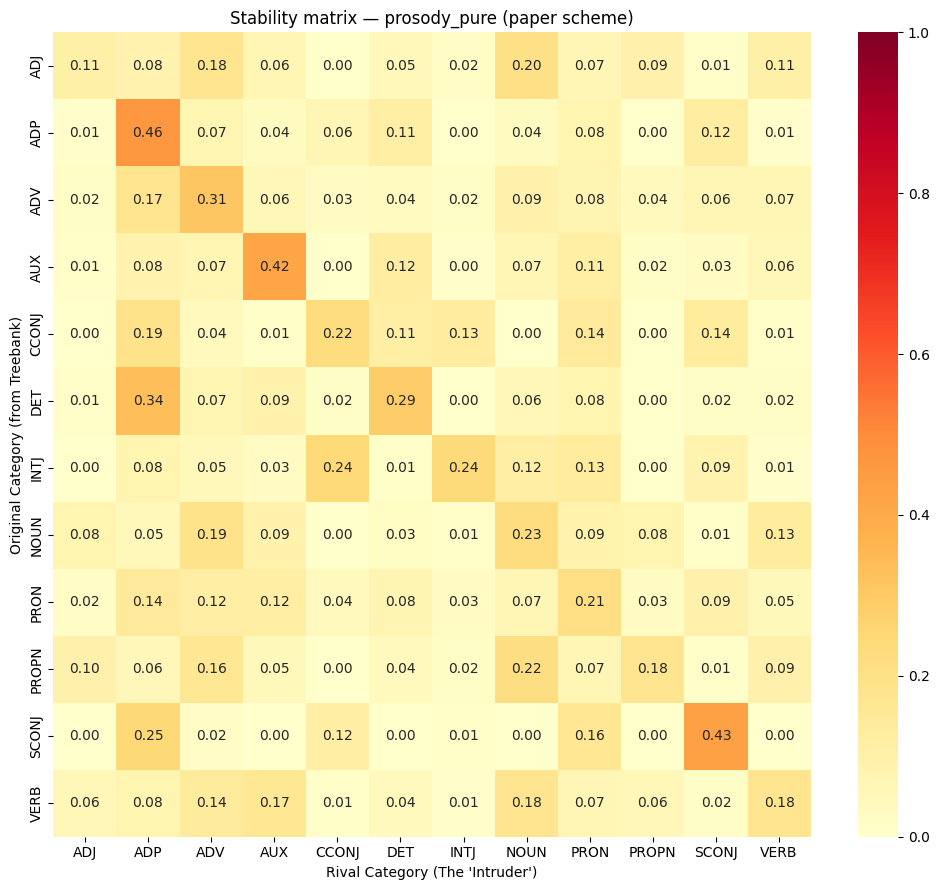

chance baseline 1/N = 0.083
mean self-stability  = 0.274
WAS (prosody_pure      ): 0.2019
WAS (syntactic         ): 0.1301
WAS (prosodic_syntactic): 0.2608
WAS (combined          ): 0.2611


In [19]:
scores_by_space = {s: compute_scores(sim, idx2lexunit, category_freqs)
                   for s, sim in similarities.items()}
transition_matrices = {s: build_transition_matrix(sim, idx2lexunit, category_freqs)
                       for s, sim in similarities.items()}

MAIN_SPACE = "prosody_pure"
tm = transition_matrices[MAIN_SPACE]
plot_transition_matrix(tm, f"Stability matrix — {MAIN_SPACE} "
                           f"({CONFIG['unit_scheme']} scheme)")
print(f"chance baseline 1/N = {1 / len(tm):.3f}")
print(f"mean self-stability  = {np.diag(tm.values).mean():.3f}")
for s in ("prosody_pure", "syntactic", "prosodic_syntactic", "combined"):
    if s in transition_matrices:
        print(f"WAS ({s:<18}): "
              f"{calculate_weighted_stability(transition_matrices[s], category_freqs):.4f}")


In [20]:
# ── Table 1: off-diagonal block shares, with per-class chance ─────────────
print(f"block shares — {MAIN_SPACE}\n")
table1 = block_share(transition_matrices[MAIN_SPACE])
print()
print(table1.sort_values(["block", "excess"], ascending=[True, False])
            .round(3).to_string())


block shares — prosody_pure

          in_block_share  chance  excess
block                                   
content            0.566   0.364   0.202
function           0.779   0.545   0.233

             block  in_block_share  chance  excess
category                                          
PROPN      content           0.694   0.364   0.331
ADJ        content           0.649   0.364   0.286
NOUN       content           0.627   0.364   0.264
VERB       content           0.530   0.364   0.166
ADV        content           0.328   0.364  -0.035
SCONJ     function           0.961   0.545   0.416
CCONJ     function           0.931   0.545   0.386
ADP       function           0.772   0.545   0.227
DET       function           0.771   0.545   0.225
INTJ      function           0.763   0.545   0.217
PRON      function           0.640   0.545   0.095
AUX       function           0.612   0.545   0.067


In [21]:
# ── Word-length controls (old cells 26–27) ────────────────────────────────
# 1. length-blind: drop childSyl2+ columns (their zero-pattern encodes length)
# 2. monosyllabic: full columns, 1-syllable units only
# Plus the reviewer baseline: how well does syllable count ALONE predict the block?

syl_df["block"] = [block_of(c) for c in syl_df["POS"]]
mono_rule_hit = (syl_df["n_syl"] == 1) == (syl_df["block"] == "function")
print(f"'monosyllabic => function word' accuracy: "
      f"{mono_rule_hit.mean():.3f} (types), "
      f"{np.average(mono_rule_hit, weights=syl_df['n_occ']):.3f} (tokens)\n")

_length_revealing = np.array([
    (int(m.group(1)) if (m := SYL_SLOT_RE.search(f)) else 0) >= 2
    for f in idx2feature.values()])
length_blind_mask = prosody_pure_mask & ~_length_revealing
SPACE_MASKS["prosody_length_blind"] = length_blind_mask
similarities["prosody_length_blind"] = cosine_similarity(
    feature_matrix[:, length_blind_mask])
transition_matrices["prosody_length_blind"] = build_transition_matrix(
    similarities["prosody_length_blind"], idx2lexunit, category_freqs)

print("control 1 — length-blind columns, all words:")
block_share(transition_matrices["prosody_length_blind"])


def restricted_matrix(row_mask, space="prosody_pure", weight_by=None):
    """Stability matrix over a subset of units; category freqs recomputed
    inside the subset so p_norm stays correct."""
    weight_by = weight_by or CONFIG["freq_weighting"]
    keep = np.where(row_mask)[0]
    sub_idx2lexunit = {new: idx2lexunit[old] for new, old in enumerate(keep)}
    mask = SPACE_MASKS[space]
    X = feature_matrix if mask is None else feature_matrix[:, mask]
    sub_sim = cosine_similarity(X[keep])
    sub_freqs = make_category_freqs(sub_idx2lexunit, n_occ[keep], weight_by)
    return build_transition_matrix(sub_sim, sub_idx2lexunit, sub_freqs)


print("\ncontrol 2 — monosyllabic units only:")
mono_mask = n_syl == 1
print(f"({int(mono_mask.sum())} / {len(n_syl)} units)")
if mono_mask.sum() > 1:
    block_share(restricted_matrix(mono_mask))
else:
    print("subset empty — skipped")


'monosyllabic => function word' accuracy: 0.794 (types), 0.596 (tokens)

control 1 — length-blind columns, all words:
          in_block_share  chance  excess
block                                   
content            0.548   0.364   0.184
function           0.786   0.545   0.241

control 2 — monosyllabic units only:
(980 / 4859 units)
          in_block_share  chance  excess
block                                   
content            0.435   0.364   0.071
function           0.799   0.545   0.254


## §7 Experiment A — annotation-layer comparison (supervisor point 3)

Rhapsodie mixes two kinds of prosodic annotation: signal-derived (automatic
acoustics + SLAM contours) and perception-derived (S/W/_ prominence judgments,
from which the whole Foot/Group/Package structure is built — see TLT 2025
paper §3.2). Native annotators may be influenced by syntax, so any categorial
signal carried only by the perceptual layer is potentially circular.

This section runs the same stability analysis in each layer. Reading guide:
- signal_strict recovers the result → circularity answered with evidence;
- only perceptual_struct recovers it → honest reframing + discussion with Anne;
- partial (what the first run showed) → quantify the decomposition. First-run
  finding worth keeping in view: **contours carry the function-word signal
  (cliticity / ADP attractor), structure carries the content-word signal
  (edge positions)** — the asymmetry claim is layer-dependent.


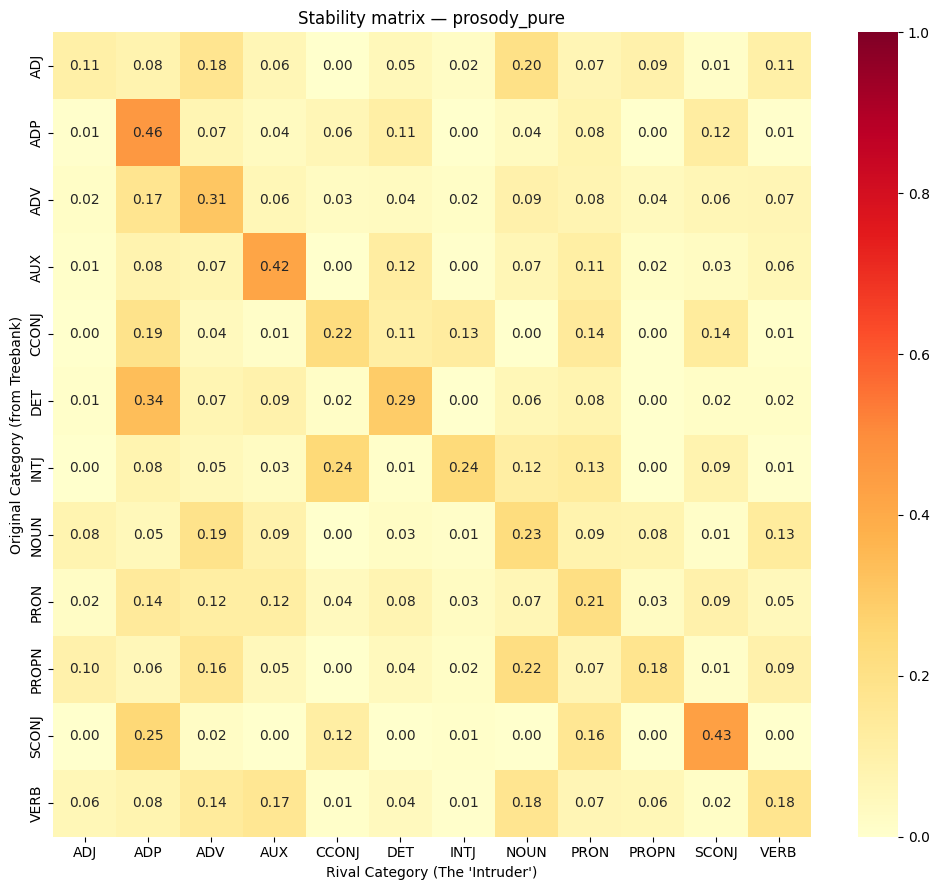

=== prosody_pure ===


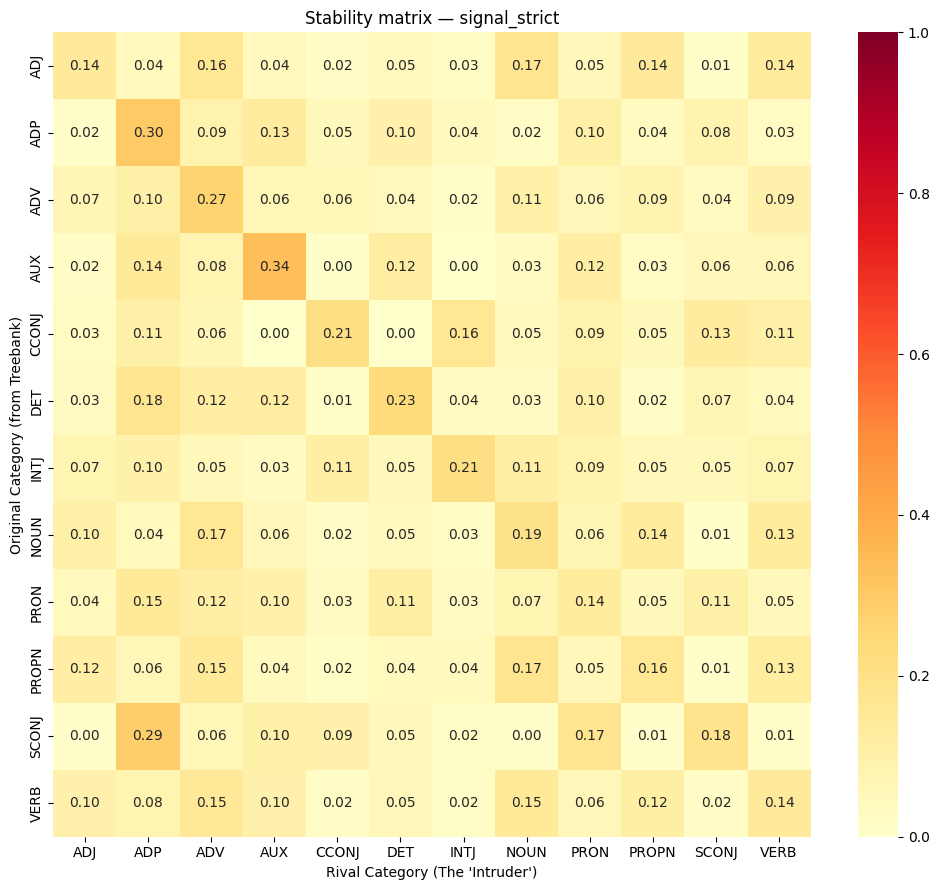

=== signal_strict ===


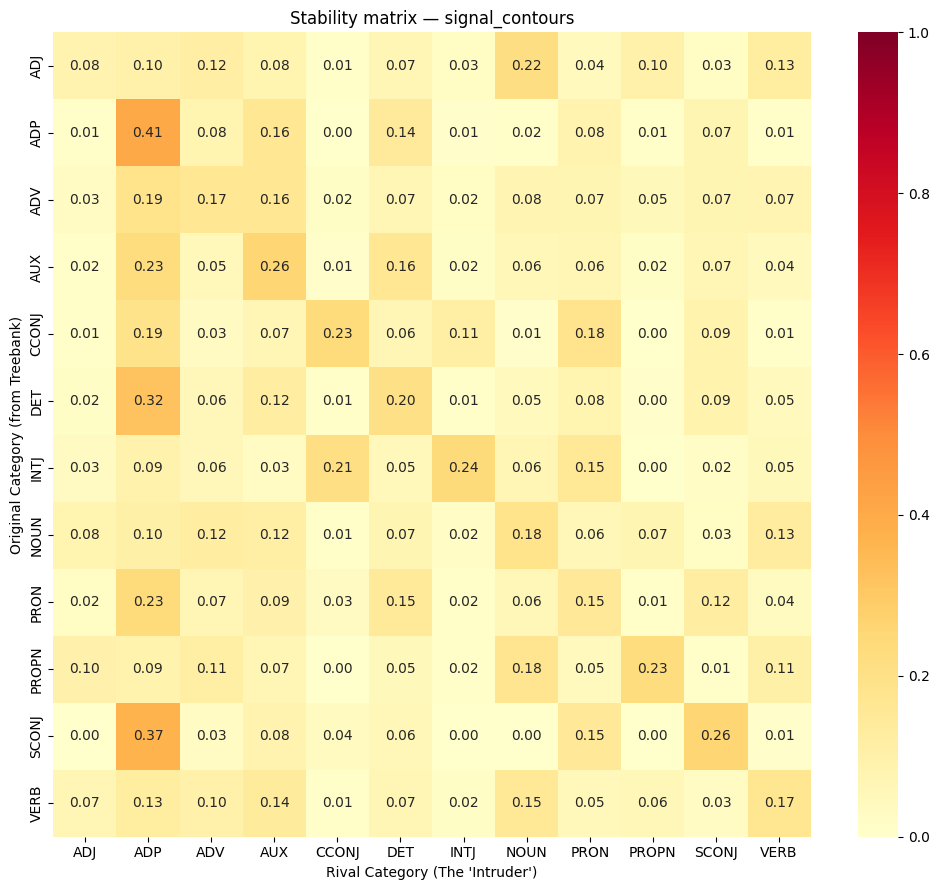

=== signal_contours ===


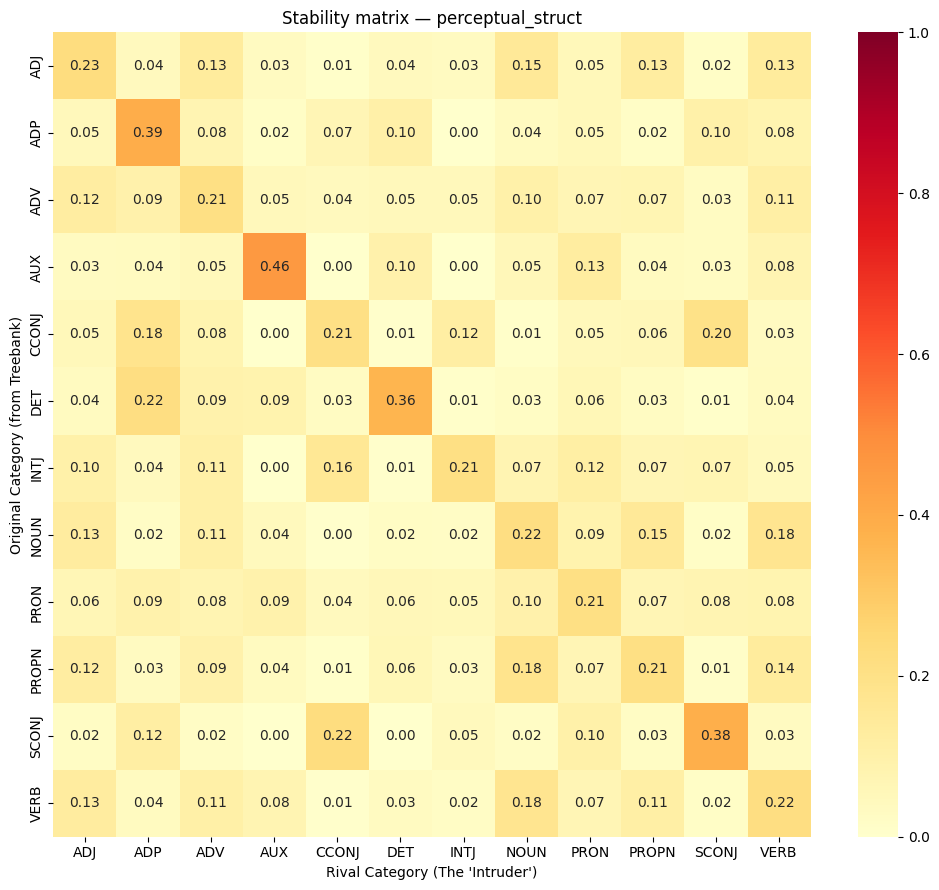

=== perceptual_struct ===

══ ANNOTATION-LAYER SUMMARY ══
                   n_columns  mean_diag  x_chance  func_in_block  func_excess  cont_in_block  cont_excess  Q_rank  best_split_is_fc
space                                                                                                                              
prosody_pure             604      0.274     3.288          0.779        0.233          0.566        0.202       2             False
signal_strict            124      0.210     2.519          0.680        0.135          0.630        0.266       1              True
signal_contours          448      0.216     2.587          0.810        0.265          0.498        0.135       1              True
perceptual_struct        144      0.275     3.303          0.610        0.065          0.657        0.293       1              True


In [22]:
LAYER_SPACES = ["prosody_pure", "signal_strict", "signal_contours",
                "perceptual_struct"]

layer_summary = []
for space in LAYER_SPACES:
    tm_s = transition_matrices[space]
    plot_transition_matrix(tm_s, f"Stability matrix — {space}")
    print(f"=== {space} ===")
    shares = block_share(tm_s, verbose=False)
    agg = shares.groupby("block")[["in_block_share", "chance", "excess"]].mean()
    ev = evaluate_split(tm_s, label=space, verbose=False)
    layer_summary.append({
        "space": space,
        "n_columns": (feature_matrix.shape[1] if SPACE_MASKS[space] is None
                      else int(SPACE_MASKS[space].sum())),
        "mean_diag": float(np.diag(tm_s.values).mean()),
        "x_chance": float(np.diag(tm_s.values).mean() * len(tm_s)),
        "func_in_block": float(agg.loc["function", "in_block_share"]),
        "func_excess": float(agg.loc["function", "excess"]),
        "cont_in_block": float(agg.loc["content", "in_block_share"]),
        "cont_excess": float(agg.loc["content", "excess"]),
        "Q_rank": ev["rank"],
        "best_split_is_fc": ev["recovers_split"],
    })

layer_df = pd.DataFrame(layer_summary).set_index("space")
print("\n══ ANNOTATION-LAYER SUMMARY ══")
print(layer_df.round(3).to_string())


## §8 Experiment B — revised categories: designed predictions (points 1–2)

Only meaningful with `unit_scheme="revised"`. The point of the new categories
is that the paper's post-hoc interpretations become predictions:

1. **ADJ→NOUN was postnominal position** → ADJ_post→NOUN should be strong,
   ADJ_pre→NOUN weak, ADJ_other elsewhere (predicative behaviour).
2. **VERB→AUX was VerbForm heterogeneity + deaccenting** → the three
   VERB:VerbForm rows should behave differently around AUX; if VERB:Part
   leans on AUX:aux, that is the participle phrased with its auxiliary.
3. **DET→ADP (shared proclisis)** should survive unchanged — it never
   depended on the unit definition.
4. **PRON_ton vs PRON_aton**: atonic with the function block; where the tonic
   pronouns land is an open, genuinely interesting question.
5. **AUX:aux vs AUX:cop**: do auxiliary and copula uses of the same forms
   diverge prosodically at all?


In [23]:
def report_cells(tm, pairs, note=""):
    """Print tm[row, col] for each (row, col), with the row's self-stability."""
    if note:
        print(note)
    for row, col in pairs:
        if row not in tm.index or col not in tm.columns:
            print(f"  {row:12s} -> {col:12s}   (category not in matrix)")
            continue
        print(f"  {row:12s} -> {col:12s}  {tm.loc[row, col]:.3f}   "
              f"(self-stability {row}: {tm.loc[row, row]:.3f})")


if CONFIG["unit_scheme"] == "revised":
    tm_r = transition_matrices[MAIN_SPACE]
    report_cells(tm_r, [("ADJ_post", "NOUN"), ("ADJ_pre", "NOUN"),
                        ("ADJ_other", "NOUN")],
                 "P1 — adjective position (expect post >> pre):")
    report_cells(tm_r, [("VERB:Part", "AUX:aux"), ("VERB:Fin", "AUX:aux"),
                        ("VERB:Inf", "AUX:aux")],
                 "\nP2 — VerbForm around AUX:")
    report_cells(tm_r, [("DET", "ADP")],
                 "\nP3 — proclisis overlap (expect it to survive):")
    report_cells(tm_r, [("PRON_aton", "PRON_ton"), ("PRON_ton", "PRON_aton")],
                 "\nP4 — pronoun tonicity:")
    print("\nP4b — where do the pronoun classes' neighbours live?")
    _pron_rows = [c for c in tm_r.index if c.startswith("PRON")]
    print(block_share(tm_r, verbose=False).reindex(_pron_rows)
          .round(3).to_string())
    report_cells(tm_r, [("AUX:aux", "AUX:cop"), ("AUX:cop", "AUX:aux")],
                 "\nP5 — auxiliary vs copula:")
else:
    print("unit_scheme='paper' — set CONFIG['unit_scheme']='revised' and "
          "rerun from §3 to test the designed predictions.")


unit_scheme='paper' — set CONFIG['unit_scheme']='revised' and rerun from §3 to test the designed predictions.


## §9 Overlap analysis — bridge words, pulling features, radar charts

The chain that produces the paper's §4.2 material: select bridge words →
find which features build the overlap → contrast the bridge set against both
category poles (with the length-proxy flag) → radar chart.
Kept: old cells 28, 32, 35, 43–44, 57, 65–68. Removed: the non-mass pulling
functions and the first bridge_contrast, which these superseded.


In [24]:
# ── Bridge-word selection ─────────────────────────────────────────────────

def get_top_bridge_words(scores_dict, original_cat, rival_cat, top_n=100):
    """Units of original_cat whose strongest rival is rival_cat, least pure first."""
    matches_ = [
        {"word": w, "purity": float(d["purity"]), "entropy": float(d["entropy"])}
        for (w, c), d in scores_dict.items()
        if c == original_cat and d["rival_category"] == rival_cat
    ]
    matches_.sort(key=lambda x: x["purity"])
    return [(m["word"], f'{m["purity"]:.2f}', f'{m["entropy"]:.2f}')
            for m in matches_[:top_n]]


def bridge_table(scores, original_cat, rival_cat):
    rows = []
    for (word, cat), d in scores.items():
        if cat != original_cat or d["rival_category"] != rival_cat:
            continue
        p, r = float(d["purity"]), float(d["rival_weight_ratio"])
        rows.append({"word": word, "purity": p, "rival_share": r,
                     "entropy": float(d["entropy"]),
                     "concentration": p + r,   # mass in just these two categories
                     "bridge_score": r - p})   # >0 = more rival-like than own-like
    cols = ["word", "purity", "rival_share", "entropy",
            "concentration", "bridge_score"]
    return (pd.DataFrame(rows, columns=cols)
              .sort_values("bridge_score", ascending=False))


def select_bridge_words(scores, original_cat, rival_cat,
                        min_bridge_score=0.0, min_concentration=0.7, max_n=None):
    t = bridge_table(scores, original_cat, rival_cat)
    t = t[(t["bridge_score"] >= min_bridge_score) &
          (t["concentration"] >= min_concentration)]
    return t.head(max_n)["word"].tolist() if max_n else t["word"].tolist()


In [25]:
# ── Which features BUILD an overlap (by cosine mass) ──────────────────────

def get_pulling_features_by_mass(lex_unit, rival_category, space=None,
                                 top_k_features=20,
                                 sim_threshold=None, max_neighbours=None):
    """Rank features by their contribution to the unit<->rival cosine
    similarity: û_i · r̂_i, summing to the mean cosine with the rival
    neighbours; `share` = fraction of the overlap each feature carries."""
    space = space or MAIN_SPACE
    sim_threshold = sim_threshold or CONFIG["sim_threshold"]
    max_neighbours = max_neighbours or CONFIG["max_neighbours"]
    similarity_matrix = similarities[space]
    mask = SPACE_MASKS[space]
    cols = np.arange(feature_matrix.shape[1]) if mask is None else np.where(mask)[0]

    unit_idx = lexunit2idx[lex_unit]
    u = feature_matrix[unit_idx, cols].astype(float)
    if np.linalg.norm(u) == 0:
        return []
    u_hat = u / np.linalg.norm(u)

    cand = np.where(similarity_matrix[unit_idx] >= sim_threshold)[0]
    neigh = sorted([i for i in cand if i != unit_idx],
                   key=lambda i: similarity_matrix[unit_idx][i],
                   reverse=True)[:max_neighbours]
    rival_ids = [i for i in neigh if idx2lexunit[i][1] == rival_category]
    if not rival_ids:
        return []

    R = feature_matrix[np.ix_(rival_ids, cols)].astype(float)
    rn = np.linalg.norm(R, axis=1, keepdims=True)
    rn[rn == 0] = 1.0
    r_hat = (R / rn).mean(axis=0)

    contribution = u_hat * r_hat
    total = contribution.sum()
    rows = []
    for li in np.argsort(contribution)[::-1][:top_k_features]:
        c = contribution[li]
        if c <= 0:
            continue
        rows.append({"feature": idx2feature[int(cols[li])],
                     "unit_value": float(u[li]), "rival_dir": float(r_hat[li]),
                     "contribution": float(c),
                     "share": float(c / total) if total > 0 else 0.0})
    return rows


def get_aggregate_pulling_features_by_mass(original_cat, rival_cat, space=None,
                                           top_k_words=10, top_k_features=20):
    space = space or MAIN_SPACE
    bridge_words = get_top_bridge_words(scores_by_space[space], original_cat,
                                        rival_cat, top_n=top_k_words)
    if not bridge_words:
        print(f"No bridge words {original_cat} -> {rival_cat}")
        return None
    per_feature = {}
    for word, _p, _e in bridge_words:
        lu = (word, original_cat)
        if lu not in lexunit2idx:
            continue
        for fd in get_pulling_features_by_mass(lu, rival_cat, space=space,
                                               top_k_features=top_k_features * 3):
            d = per_feature.setdefault(fd["feature"],
                                       {"contribs": [], "unit_values": []})
            d["contribs"].append(fd["contribution"])
            d["unit_values"].append(fd["unit_value"])
    if not per_feature:
        return None
    rows = [{"feature": f, "count_words": len(d["contribs"]),
             "total_contrib": float(np.sum(d["contribs"])),
             "avg_contrib": float(np.mean(d["contribs"])),
             "avg_unit_value": float(np.mean(d["unit_values"]))}
            for f, d in per_feature.items()]
    rows.sort(key=lambda r: r["total_contrib"], reverse=True)
    return pd.DataFrame(rows[:top_k_features])


In [26]:
# ── bridge_contrast: bridge set vs both category poles ────────────────────
# The revised version (old cell 57): symmetric pole definitions, no purity
# filter contamination, and childSyl2+ features one pole essentially never
# fills are flagged as LENGTH PROXIES rather than reported as pitch/duration
# effects. This produces the group-percentage numbers quoted in paper §4.2.

def _pole(cat, exclude_ids, reference, scores, quantile):
    ids = np.array([i for i, lu in idx2lexunit.items()
                    if lu[1] == cat and i not in exclude_ids], dtype=int)
    if len(ids) == 0:
        raise ValueError(f"no units left for {cat}")
    if reference == "centroid":
        return ids, np.ones(len(ids))
    pur = np.array([scores.get(idx2lexunit[i], {}).get("purity", 0.0) for i in ids])
    if reference == "purity_weighted":
        return ids, pur
    if reference == "high_purity":
        keep = pur >= np.quantile(pur, quantile)
        return ids[keep], np.ones(int(keep.sum()))
    raise ValueError(f"unknown reference: {reference}")


def bridge_contrast(original_cat, rival_cat, space=None, n_bridge=40,
                    reference="centroid", quantile=0.75,
                    min_separation=0.10, flag_length_proxies=True):
    space = space or MAIN_SPACE
    scores = scores_by_space[space]
    bridge_units = {(d[0], original_cat)
                    for d in get_top_bridge_words(scores, original_cat,
                                                  rival_cat, top_n=n_bridge)}
    bridge_ids = np.array([lexunit2idx[u] for u in bridge_units
                           if u in lexunit2idx], dtype=int)
    if len(bridge_ids) == 0:
        print(f"{original_cat} -> {rival_cat}: no bridge words in this space")
        return None
    excl = set(bridge_ids.tolist())

    orig_ids, orig_w = _pole(original_cat, excl, reference, scores, quantile)
    rival_ids, rival_w = _pole(rival_cat, excl, reference, scores, quantile)

    mask = SPACE_MASKS[space]
    cols = np.arange(feature_matrix.shape[1]) if mask is None else np.where(mask)[0]
    names = [idx2feature[c] for c in cols]
    X = feature_matrix[:, cols]

    m_orig  = np.average(X[orig_ids], axis=0, weights=orig_w)
    m_rival = np.average(X[rival_ids], axis=0, weights=rival_w)
    m_bridge = X[bridge_ids].mean(axis=0)

    sep = m_rival - m_orig
    with np.errstate(divide="ignore", invalid="ignore"):
        pos = np.where(np.abs(sep) > 1e-9, (m_bridge - m_orig) / sep, np.nan)

    slot = [int(m.group(1)) if (m := SYL_SLOT_RE.search(f)) else 0 for f in names]
    is_proxy = np.array([s >= 2 and (mo < 0.05 or mr < 0.05)
                         for s, mo, mr in zip(slot, m_orig, m_rival)])

    df = pd.DataFrame({
        "feature": names,
        f"mean_{original_cat}": m_orig, "mean_bridge": m_bridge,
        f"mean_{rival_cat}": m_rival,
        "separation": sep, "abs_separation": np.abs(sep),
        "bridge_position": pos, "syl_slot": slot, "length_proxy": is_proxy,
    })
    df = df[df["abs_separation"] >= min_separation]
    df = df.sort_values("abs_separation", ascending=False).reset_index(drop=True)

    clean = df[~df["length_proxy"]] if flag_length_proxies else df
    print(f"{original_cat} -> {rival_cat}  [{space}, reference={reference}]")
    print(f"poles: {len(orig_ids)} {original_cat}, {len(rival_ids)} {rival_cat}; "
          f"{len(bridge_ids)} bridge words (excluded from both poles)")
    print(f"{len(df)} features separate the poles by >= {min_separation}"
          + (f"  ({int(df['length_proxy'].sum())} length proxies)"
             if df["length_proxy"].any() else ""))
    if len(clean):
        print(f"median bridge_position (proxies excluded): "
              f"{clean['bridge_position'].median():.2f}  "
              f"(0 = like {original_cat}, 1 = like {rival_cat});  "
              f"share within [0,1]: {clean['bridge_position'].between(0, 1).mean():.1%}")
    return df


In [27]:
# ── Radar charts (old cells 65–68) ────────────────────────────────────────

def build_three_groups(scores_dict, original_cat, rival_cat,
                       n_bridge=40, stable_purity=0.8):
    bridge = [(w, original_cat)
              for w, _p, _e in get_top_bridge_words(scores_dict, original_cat,
                                                    rival_cat, top_n=n_bridge)
              if (w, original_cat) in lexunit2idx]
    rival, stable = [], []
    for (word, cat), d in scores_dict.items():
        if cat == rival_cat:
            rival.append((word, cat))
        elif cat == original_cat and d["purity"] >= stable_purity:
            stable.append((word, cat))
    return bridge, rival, stable


def _dimension_key(feature_str):
    """Collapse a column to a position-independent axis label:
    'node:X:childSyl1:PitchRangeGlo=L' -> 'PitchRange=L'."""
    m = re.match(r"^node:X:[^:]+:(?P<rest>.+)$", feature_str)
    if not m:
        return None
    prop, _, val = m.group("rest").partition("=")
    prop = prop.replace("Glo", "").replace("Loc", "")
    return f"{prop}={val}" if val else prop


def build_index_defs_from_pull(df_agg, top_n_axes=8, min_words=1):
    """{axis_label: (column_indices, sign)} from an aggregate pulling table."""
    df_agg = df_agg[df_agg["count_words"] >= min_words]
    contrib, members = defaultdict(float), defaultdict(set)
    name2idx = {f: i for i, f in idx2feature.items()}
    for _, row in df_agg.iterrows():
        key = _dimension_key(row["feature"])
        if key is None:
            continue
        contrib[key] += row["total_contrib"]
        members[key].add(name2idx[row["feature"]])
    ranked = sorted(contrib, key=contrib.get, reverse=True)[:top_n_axes]
    return {key: (sorted(members[key]), +1) for key in ranked}


def unit_indices_from_cols(lex_units, index_defs):
    rows = []
    for lu in lex_units:
        if lu not in lexunit2idx:
            continue
        r = feature_matrix[lexunit2idx[lu]]
        row = {"word": lu[0], "pos": lu[1]}
        for label, (cols, sign) in index_defs.items():
            rate = float(r[cols].sum()) if cols else np.nan
            row[label] = (1.0 - rate) if sign < 0 else rate
        rows.append(row)
    return pd.DataFrame(rows)


def _spider(means, labels, group_order, colors, title, scale_per_axis=True):
    angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
    angles += angles[:1]
    scaled = means.copy()
    if scale_per_axis:
        for col in labels:
            hi = scaled[col].max()
            scaled[col] = scaled[col] / hi if hi > 0 else 0.0
    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for g in group_order:
        vals = scaled.loc[g, labels].tolist() + [scaled.loc[g, labels[0]]]
        ax.plot(angles, vals, label=g, color=colors[g], linewidth=2)
        ax.fill(angles, vals, color=colors[g], alpha=0.08)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=9)
    ax.set_yticklabels([])
    ax.set_title(title, pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=False)
    plt.tight_layout()
    plt.show()


def spider_for_overlap(original_cat, rival_cat, space=None,
                       top_n_axes=8, n_bridge=40, stable_purity=0.8):
    space = space or MAIN_SPACE
    df_agg = get_aggregate_pulling_features_by_mass(
        original_cat, rival_cat, space=space,
        top_k_words=n_bridge, top_k_features=40)
    if df_agg is None:
        return None
    index_defs = build_index_defs_from_pull(df_agg, top_n_axes=top_n_axes)
    bridge, rival, stable = build_three_groups(
        scores_by_space[space], original_cat, rival_cat,
        n_bridge=n_bridge, stable_purity=stable_purity)
    order = [f"bridge {original_cat}", rival_cat, f"stable {original_cat}"]
    colors = {order[0]: "#c0392b", order[1]: "#e67e22", order[2]: "#2c7fb8"}
    frames = []
    for gname, group in zip(order, [bridge, rival, stable]):
        d = unit_indices_from_cols(group, index_defs)
        d["group"] = gname
        frames.append(d)
    means = (pd.concat(frames, ignore_index=True)
               .groupby("group")[list(index_defs)].mean().reindex(order))
    _spider(means, list(index_defs), order, colors,
            title=f"{original_cat} -> {rival_cat}  ({space})")
    return means



DET -> ADP  [prosody_pure, reference=centroid]
poles: 48 DET, 39 ADP; 40 bridge words (excluded from both poles)
57 features separate the poles by >= 0.1  (2 length proxies)
median bridge_position (proxies excluded): 0.46  (0 = like DET, 1 = like ADP);  share within [0,1]: 74.5%
                             feature  mean_DET  mean_bridge  mean_ADP  separation  abs_separation  bridge_position  syl_slot  length_proxy
  node:X:next:ProminenceFinal=Strong     0.630        0.610     0.341      -0.289           0.289            0.071         0         False
            node:X:next:Package=Last     0.507        0.478     0.252      -0.254           0.254            0.111         0         False
              node:X:next:Package=In     0.281        0.392     0.527       0.246           0.246            0.453         0         False
                node:X:next:Group=In     0.149        0.248     0.377       0.228           0.228            0.433         0         False
               node:X:ow

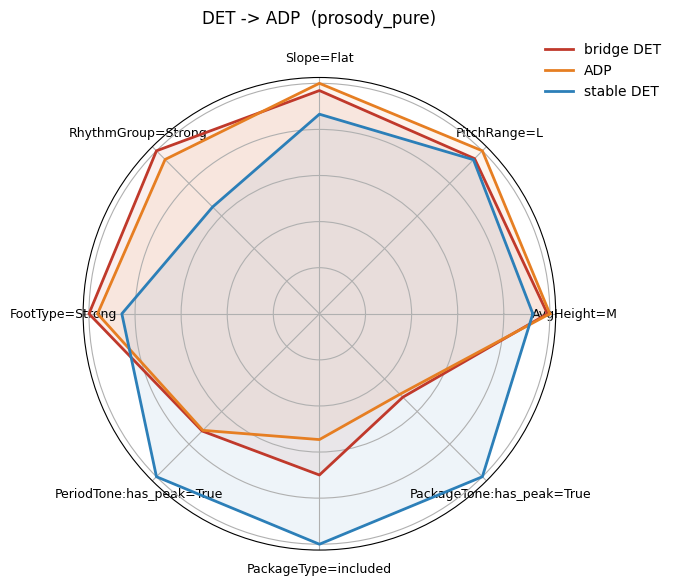


ADJ -> NOUN  [prosody_pure, reference=centroid]
poles: 599 ADJ, 1820 NOUN; 40 bridge words (excluded from both poles)
19 features separate the poles by >= 0.1
median bridge_position (proxies excluded): 0.67  (0 = like ADJ, 1 = like NOUN);  share within [0,1]: 73.7%
                          feature  mean_ADJ  mean_bridge  mean_NOUN  separation  abs_separation  bridge_position  syl_slot  length_proxy
            node:X:own:Group=Last     0.324        0.488      0.628       0.304           0.304            0.538         0         False
           node:X:prev:Group=Last     0.411        0.275      0.140      -0.271           0.271            0.502         0         False
          node:X:own:Group=Unique     0.404        0.225      0.138      -0.266           0.266            0.673         0         False
             node:X:own:Foot=Last     0.225        0.412      0.448       0.223           0.223            0.840         0         False
          node:X:prev:Group=Begin     0.172     

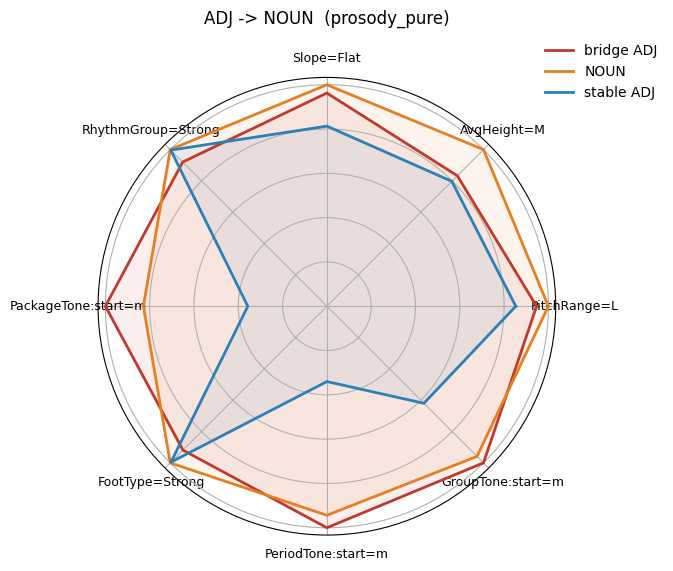


ADV -> ADP  [prosody_pure, reference=centroid]
poles: 160 ADV, 39 ADP; 40 bridge words (excluded from both poles)
62 features separate the poles by >= 0.1  (12 length proxies)
median bridge_position (proxies excluded): 0.29  (0 = like ADV, 1 = like ADP);  share within [0,1]: 80.0%
                          feature  mean_ADV  mean_bridge  mean_ADP  separation  abs_separation  bridge_position  syl_slot  length_proxy
node:X:own:ProminenceFinal=Strong     0.564        0.451     0.147      -0.417           0.417            0.271         0         False
 node:X:childSyl3:PitchRangeGlo=L     0.419        0.292     0.028      -0.391           0.391            0.325         3          True
           node:X:own:Group=Begin     0.113        0.199     0.464       0.351           0.351            0.245         0         False
  node:X:childSyl3:AvgHeightGlo=M     0.353        0.228     0.028      -0.325           0.325            0.385         3          True
         node:X:own:Package=Begin    

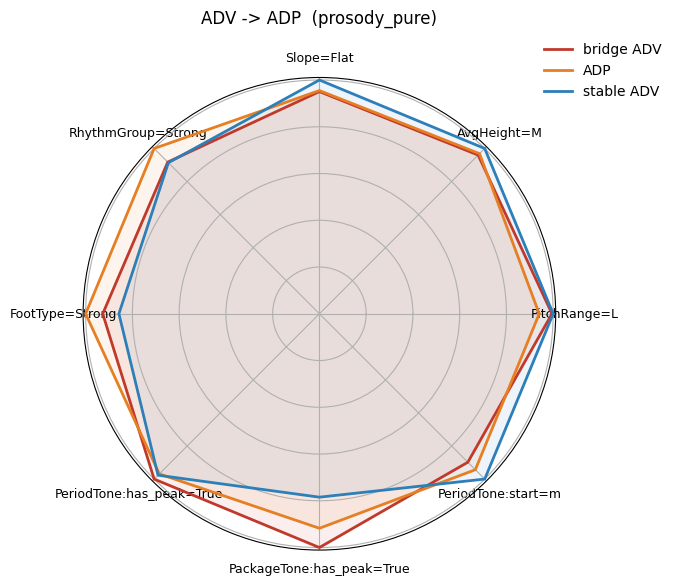


VERB -> AUX  [prosody_pure, reference=centroid]
poles: 1342 VERB, 48 AUX; 40 bridge words (excluded from both poles)
57 features separate the poles by >= 0.1  (8 length proxies)
median bridge_position (proxies excluded): 0.79  (0 = like VERB, 1 = like AUX);  share within [0,1]: 83.7%
                           feature  mean_VERB  mean_bridge  mean_AUX  separation  abs_separation  bridge_position  syl_slot  length_proxy
             node:X:own:Package=In      0.389        0.756     0.779       0.390           0.390            0.942         0         False
 node:X:own:ProminenceFinal=Strong      0.487        0.173     0.097      -0.390           0.390            0.804         0         False
               node:X:own:Group=In      0.170        0.466     0.515       0.345           0.345            0.858         0         False
           node:X:next:Group=Begin      0.460        0.209     0.145      -0.314           0.314            0.796         0         False
                node:X:o

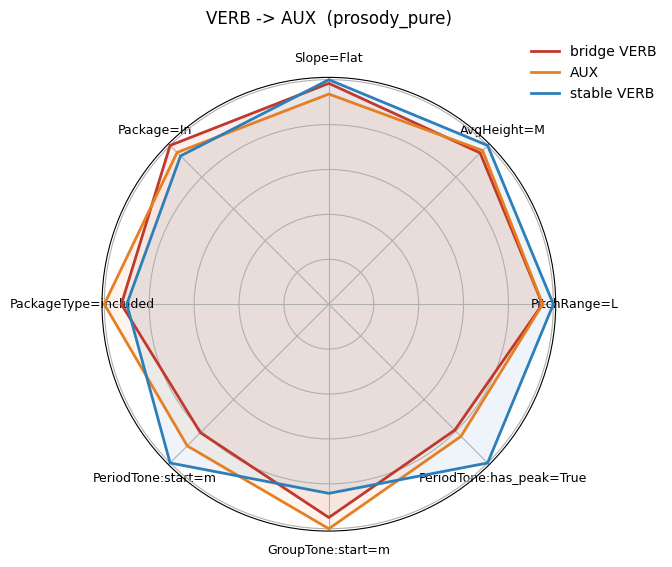

In [28]:
# ── Run the overlap analyses ──────────────────────────────────────────────
# Paper scheme: the paper's four overlaps. Revised scheme: the designed-
# prediction overlaps. Edit freely — everything above is scheme-agnostic.

if CONFIG["unit_scheme"] == "paper":
    OVERLAPS = [("DET", "ADP"), ("ADJ", "NOUN"), ("ADV", "ADP"), ("VERB", "AUX")]
else:
    OVERLAPS = [("DET", "ADP"), ("ADJ_post", "NOUN"), ("ADJ_pre", "NOUN"),
                ("VERB:Part", "AUX:aux"), ("PRON_ton", "NOUN")]

for orig, rival in OVERLAPS:
    print("\n" + "=" * 70)
    df_c = bridge_contrast(orig, rival)
    if df_c is not None and len(df_c):
        print(df_c.head(15).round(3).to_string(index=False))
        spider_for_overlap(orig, rival)


## §10 Robustness — selection & displacement nulls (old cells 40–41, 69)

Are the bridge sets coherent groups or accidents of rare, noisily estimated
forms? Frequency-matched permutation nulls, as in paper Appendix B.


In [29]:
def _freq_matched_pick(rng, pool, pool_occ, target_occ):
    pick = []
    for o in target_occ:
        cand = pool[pool_occ == o]
        if len(cand) == 0:
            cand = pool[np.abs(pool_occ - o) <= 1]
        pick.append(rng.choice(cand if len(cand) else pool))
    return pick


def selection_null(bridge_ids, original_cat, space=None, n_perm=1000, seed=0):
    """Per-feature: does the bridge group's profile differ from frequency-
    matched random same-category samples?"""
    space = space or MAIN_SPACE
    rng = np.random.default_rng(seed)
    mask = SPACE_MASKS[space]
    cols = np.arange(feature_matrix.shape[1]) if mask is None else np.where(mask)[0]
    X = feature_matrix[:, cols]

    excl = set(np.asarray(bridge_ids).tolist())
    pool = np.array([i for i, lu in idx2lexunit.items()
                     if lu[1] == original_cat and i not in excl])
    bocc = np.array([n_occ[i] for i in bridge_ids])
    pocc = np.array([n_occ[i] for i in pool])

    obs = X[np.asarray(bridge_ids)].mean(0)
    null = np.empty((n_perm, len(cols)))
    for k in range(n_perm):
        null[k] = X[_freq_matched_pick(rng, pool, pocc, bocc)].mean(0)

    mu, sd = null.mean(0), null.std(0)
    return pd.DataFrame({
        "feature": [idx2feature[c] for c in cols],
        "p_bridge": obs, "null_mean": mu, "null_sd": sd,
        "z": (obs - mu) / np.where(sd > 0, sd, 1),
        "p_value": (np.abs(null - mu) >= np.abs(obs - mu)).mean(0),
    }).sort_values("p_value")


def displacement_test(bridge_ids, original_cat, rival_cat,
                      space=None, n_perm=1000, seed=0):
    """Project the bridge centroid onto the orig->rival axis; compare against
    frequency-matched random same-category samples (paper Table B.1)."""
    space = space or MAIN_SPACE
    rng = np.random.default_rng(seed)
    mask = SPACE_MASKS[space]
    cols = np.arange(feature_matrix.shape[1]) if mask is None else np.where(mask)[0]
    X = feature_matrix[:, cols]

    bridge_ids = np.asarray(bridge_ids)
    excl = set(bridge_ids.tolist())
    pool = np.array([i for i, lu in idx2lexunit.items()
                     if lu[1] == original_cat and i not in excl])
    rival_ids = np.array([i for i, lu in idx2lexunit.items()
                          if lu[1] == rival_cat])

    p_orig, p_rival = X[pool].mean(0), X[rival_ids].mean(0)
    axis = p_rival - p_orig
    denom = axis @ axis
    proj = lambda v: float((v - p_orig) @ axis / denom)

    bocc = np.array([n_occ[i] for i in bridge_ids])
    pocc = np.array([n_occ[i] for i in pool])
    obs = proj(X[bridge_ids].mean(0))
    null = np.array([proj(X[_freq_matched_pick(rng, pool, pocc, bocc)].mean(0))
                     for _ in range(n_perm)])
    p = (null >= obs).mean()
    print(f"{original_cat}->{rival_cat}: displacement {obs:.3f}, "
          f"null {null.mean():.3f} (sd {null.std():.3f}), "
          f"z = {(obs - null.mean()) / null.std():.2f}, p = {p:.4f}")
    return obs, null


for orig, rival in OVERLAPS:
    words = select_bridge_words(scores_by_space[MAIN_SPACE], orig, rival)
    ids = np.array([lexunit2idx[(w, orig)] for w in words
                    if (w, orig) in lexunit2idx])
    if len(ids):
        displacement_test(ids, orig, rival)
    else:
        print(f"{orig}->{rival}: no bridge words")


DET->ADP: displacement 0.351, null 0.101 (sd 0.085), z = 2.92, p = 0.0000
ADJ->NOUN: displacement 0.454, null -0.114 (sd 0.161), z = 3.52, p = 0.0000
ADV->ADP: displacement 0.025, null 0.149 (sd 0.148), z = -0.84, p = 0.7870
VERB->AUX: displacement 0.790, null 0.087 (sd 0.057), z = 12.31, p = 0.0000


## §11 Experiment C — syllable-level categorisation (supervisor point 4)

Prosody lives on syllables; the word-level analysis presupposes the word as
the unit. Two direct questions, from **signal-only syllable features**
(so this doubles as another circularity-free check):

1. Can a syllable's acoustics predict that it is word-final? (polysyllabic
   words only — for monosyllables the task is degenerate)
2. Can they predict that it is the final syllable of a word of category X?

Both come with an empirical permutation baseline (labels shuffled), because
F1 on rare classes is not comparable to zero. Standalone: parses the conllu
directly, no grewpy.


In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

SYL_ACOUSTIC = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                "SemitonesFromUtteranceMean")


def read_syllables(conllu_path):
    """One dict per syllable: acoustics + word-level info (upos, position)."""
    tokens, syls = {}, defaultdict(list)

    def flush():
        for tid, sy in syls.items():
            tok = tokens.get(tid)
            if tok is None:
                continue
            n = len(sy)
            for k, s in enumerate(sy):
                yield {"upos": tok["upos"], "form": tok["form"],
                       "n_syl_word": n,
                       "is_initial": k == 0, "is_final": k == n - 1,
                       **{f: s.get(f) for f in SYL_ACOUSTIC}}
        tokens.clear()
        syls.clear()

    with open(conllu_path, encoding="utf-8") as fh:
        for line in fh:
            line = line.rstrip("\n")
            if not line:
                yield from flush()
                continue
            if line.startswith("#"):
                continue
            cols = line.split("\t")
            tid, form, _lemma, upos = cols[0], cols[1], cols[2], cols[3]
            misc = dict(kv.split("=", 1) for kv in cols[9].split("|") if "=" in kv)
            if "." in tid:
                syls[tid.split(".")[0]].append(misc)
            elif upos != "PUNCT":
                tokens[tid] = {"form": form, "upos": upos, **misc}
        yield from flush()


syl_data = pd.DataFrame(read_syllables(TREEBANK_PATH))
syl_data["Duration"] = pd.to_numeric(syl_data["Duration"], errors="coerce")
syl_data["SemitonesFromUtteranceMean"] = pd.to_numeric(
    syl_data["SemitonesFromUtteranceMean"], errors="coerce")
syl_data = syl_data.dropna(subset=["Duration"]).reset_index(drop=True)
print(f"{len(syl_data)} syllables "
      f"({(syl_data.n_syl_word >= 2).mean():.0%} in polysyllabic words)")


40894 syllables (51% in polysyllabic words)


In [31]:
def _design(df):
    X = pd.get_dummies(df[["AvgHeightGlo", "PitchRangeGlo", "SlopeGlo"]],
                       dummy_na=True)
    X["Duration"] = df["Duration"].values
    X["Semitones"] = df["SemitonesFromUtteranceMean"].fillna(0).values
    return X.astype(float).values


def _clf():
    return make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=2000,
                                            class_weight="balanced"))


def permutation_f1(X, y, n_perm=10, seed=0):
    """Empirical chance F1: shuffle labels, refit, cross-validated F1."""
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_perm):
        y_s = rng.permutation(y)
        out.append(f1_score(y_s, cross_val_predict(_clf(), X, y_s, cv=5)))
    return float(np.mean(out)), float(np.std(out))


# ── (i) word-final syllable, polysyllabic words ───────────────────────────
poly = syl_data[syl_data.n_syl_word >= 2]
Xp, yp = _design(poly), poly["is_final"].values
acc = cross_val_score(_clf(), Xp, yp, cv=5).mean()
base = cross_val_score(DummyClassifier(strategy="most_frequent"),
                       Xp, yp, cv=5).mean()
print(f"(i) word-final syllable (polysyllabic): acc {acc:.3f} "
      f"vs majority {base:.3f}  (n={len(poly)})")

# ── (ii) final syllable of a word of category X ───────────────────────────
Xa = _design(syl_data)
print("\n(ii) final-of-category, F1 vs permutation chance:")
for cat in ("NOUN", "VERB", "ADJ", "ADP", "DET", "PRON"):
    y = (syl_data["is_final"] & (syl_data["upos"] == cat)).values
    obs = f1_score(y, cross_val_predict(_clf(), Xa, y, cv=5))
    chance_mu, chance_sd = permutation_f1(Xa, y, n_perm=10)
    print(f"  {cat:5s}: F1 {obs:.3f}   chance {chance_mu:.3f} "
          f"(sd {chance_sd:.3f})   base rate {y.mean():.3f}")


(i) word-final syllable (polysyllabic): acc 0.678 vs majority 0.580  (n=20817)

(ii) final-of-category, F1 vs permutation chance:
  NOUN : F1 0.341   chance 0.183 (sd 0.011)   base rate 0.119
  VERB : F1 0.183   chance 0.149 (sd 0.006)   base rate 0.088
  ADJ  : F1 0.120   chance 0.066 (sd 0.003)   base rate 0.035
  ADP  : F1 0.219   chance 0.155 (sd 0.008)   base rate 0.091
  DET  : F1 0.192   chance 0.138 (sd 0.005)   base rate 0.080
  PRON : F1 0.202   chance 0.157 (sd 0.006)   base rate 0.094


## Open questions (for the visio / Anne)

1. **Block membership of the new categories** — is PRON_ton function or
   content? VERB:Part? (`BLOCK_OVERRIDES` in §5 tests the alternatives; the
   matrix itself may answer.)
2. **Homograph pronouns** (*lui, elle, nous, vous*) — defaulted to clitic;
   worth resolving per occurrence via deprel?
3. **Idioms** — the paper excludes them; `include_idioms=True` tests them as
   own categories instead (prediction: NOUN_idiom clusters with ADP).
4. **Annotation bias** (for Anne) — the perceptual prominence layer may
   encode annotators' syntactic knowledge; Experiment A quantifies how much
   of the categorial signal needs that layer. First run: contours carry the
   function-word signal, structure the content-word signal.
5. **AUX patterns** — verify comp:aux / comp:pred against the current
   release; check the AUX:other count is small.
